# Churn télécom — Comparer les variables d’origine

Analyser les huit variables disponibles, choisir celles à garder, puis comparer les modèles.
Aucune nouvelle feature n’est créée.

**Règles communes :** séparation par client, 500 itérations, poids des classes et seuil de **0,5**.
Cette validation mesure la généralisation à d’autres clients ; elle ne simule pas une prévision future.


## 1. Fonctions communes

Les imports et les fonctions sont regroupés ici. La partie 2 lance les analyses et les modèles.


In [13]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from catboost import CatBoostClassifier, EFstrType
from IPython.display import display
from matplotlib.ticker import PercentFormatter
from sklearn.metrics import (
    average_precision_score, confusion_matrix, f1_score, log_loss,
    matthews_corrcoef, precision_score, recall_score, roc_auc_score,
)
from sklearn.model_selection import StratifiedGroupKFold

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from settings import settings

SEED = 42
HOLDOUT_SPLITS = 5  # Un groupe sur cinq réservé au test final.
CV_SPLITS = 4
MAX_ITERATIONS = 500
THRESHOLD = 0.5

MODEL_FEATURES = [
    "contract", "channel", "monthly_fee", "data_gb",
    "support_calls_3m", "late_payments", "nps", "last_invoice_amount",
]
CATEGORICAL_FEATURES = ["contract", "channel"]
NUMERIC_FEATURES = [f for f in MODEL_FEATURES if f not in CATEGORICAL_FEATURES]


### Préparer les données et les groupes

Les copies exactes sont retirées. Les mesures invalides deviennent manquantes.
Toutes les observations d’un client restent ensemble : environ 20 % des clients au test,
puis quatre folds sur les autres clients. Les deux modèles partagent ces découpages.


In [14]:
def prepare_data(path: Path) -> pd.DataFrame:
    data = pd.read_csv(path, dtype={"customer_id": "string"})
    required = ["customer_id", "snapshot_date", "churn"] + MODEL_FEATURES
    missing = set(required) - set(data.columns)
    if missing:
        raise ValueError(f"Colonnes absentes : {sorted(missing)}")

    raw_count = len(data)
    data = data.drop_duplicates().copy()
    copies_removed = raw_count - len(data)
    data["customer_id"] = data["customer_id"].str.strip()
    data["snapshot_date"] = pd.to_datetime(data["snapshot_date"], errors="coerce")
    if data["customer_id"].fillna("").eq("").any() or data["snapshot_date"].isna().any():
        raise ValueError("Identifiant client ou date de snapshot invalide.")

    # Deux lignes différentes du même client dans un mois : ne pas choisir arbitrairement.
    months = data["snapshot_date"].dt.to_period("M")
    ambiguous = data.assign(month=months).duplicated(["customer_id", "month"], keep=False)
    data = data.loc[~ambiguous, required].copy()
    for feature in CATEGORICAL_FEATURES:
        data[feature] = (
            data[feature].astype("string").str.strip().str.strip("\"'").str.lower()
            .replace("", pd.NA)
        )
    for feature in NUMERIC_FEATURES:
        values = pd.to_numeric(data[feature], errors="coerce")
        data[feature] = values.where(np.isfinite(values) & (values >= 0))
    data["nps"] = data["nps"].where(data["nps"].between(0, 10))
    data["churn"] = pd.to_numeric(data["churn"], errors="raise")
    if not data["churn"].dropna().isin([0, 1]).all():
        raise ValueError("La cible churn doit valoir 0 ou 1.")
    unlabelled = int(data["churn"].isna().sum())
    data = data.dropna(subset=["churn"]).reset_index(drop=True)
    data["churn"] = data["churn"].astype(int)
    print(f"{len(data):,} lignes ; {data['customer_id'].nunique():,} clients.")
    print(f"Retraits : {copies_removed} copies, {ambiguous.sum()} lignes ambiguës, {unlabelled} sans cible.")
    return data


def assert_group_separation(parts: dict):
    seen = set()
    for name, part in parts.items():
        if part.empty or part["churn"].nunique() != 2:
            raise ValueError(f"{name} doit contenir les deux classes.")
        clients = set(part["customer_id"])
        assert seen.isdisjoint(clients), "Client partagé entre deux partitions."
        seen.update(clients)


def make_grouped_splits(data: pd.DataFrame) -> dict:
    if data[["customer_id", "churn"]].isna().any().any():
        raise ValueError("Identifiants et cibles manquants avant le split.")
    data = data.reset_index(drop=True)
    holdout = StratifiedGroupKFold(HOLDOUT_SPLITS, shuffle=True, random_state=SEED)
    dev_index, test_index = next(holdout.split(data, data["churn"], data["customer_id"]))
    development, test = data.iloc[dev_index].copy(), data.iloc[test_index].copy()
    assert_group_separation({"development": development, "test": test})

    cv = StratifiedGroupKFold(CV_SPLITS, shuffle=True, random_state=SEED)
    cv_splits = {}
    for number, (train_index, valid_index) in enumerate(
        cv.split(development, development["churn"], development["customer_id"]), start=1,
    ):
        parts = {
            "train": development.iloc[train_index].copy(),
            "score": development.iloc[valid_index].copy(),
        }
        assert_group_separation({**parts, "test": test})
        cv_splits[f"Fold {number}"] = parts

    return {"development": development, "test": test, "cv_splits": cv_splits,
            "final_split": {"train": development, "score": test}}


### Analyser et choisir les colonnes

Les graphiques décrivent les effectifs et le churn par modalité ou tranche numérique.
Les tranches servent seulement à l’analyse. La sélection reste une liste de noms, sans entraînement automatique.


In [15]:
def plot_group_analysis(data: pd.DataFrame, features: list):
    for feature in features:
        values = data[feature]
        groups = values
        if feature in NUMERIC_FEATURES and values.nunique() > 10:
            groups = pd.qcut(values, q=5, duplicates="drop")
        table = data.assign(groupe=groups).groupby(
            "groupe", observed=True, dropna=False,
        ).agg(observations=("churn", "size"), taux_churn=("churn", "mean")).reset_index()
        labels = table["groupe"].astype("string").fillna("Non renseigné")
        fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
        axes[0].bar(labels, table["observations"], color="#2563EB")
        axes[0].set_title("Nombre d’observations")
        axes[1].bar(labels, table["taux_churn"], color="#E11D48")
        axes[1].set_title("Taux de churn observé")
        axes[1].yaxis.set_major_formatter(PercentFormatter(xmax=1))
        for ax in axes:
            ax.tick_params(axis="x", labelrotation=35)
        fig.suptitle(f"{feature} — train du premier fold")
        plt.show()
        plt.close(fig)


def select_features(features_to_keep: list, available_features: list,
                    categorical_features: list) -> dict:
    if not features_to_keep:
        raise ValueError("Choisir au moins une variable.")
    if len(features_to_keep) != len(set(features_to_keep)):
        raise ValueError("La sélection contient des doublons.")
    unknown = set(features_to_keep) - set(available_features)
    if unknown:
        raise ValueError(f"Variables inconnues ou exclues : {sorted(unknown)}")
    return {
        "features": features_to_keep.copy(),
        "categorical_features": [f for f in categorical_features if f in features_to_keep],
        "decisions": pd.DataFrame({
            "feature": available_features,
            "décision": ["Conservée" if f in features_to_keep else "Retirée" for f in available_features],
        }),
    }


### Entraîner et mesurer

Chaque modèle effectue 500 itérations, sans early stopping ni optimisation de seuil.
Dans les folds, la validation sert seulement au suivi des courbes et aux scores.
Le modèle final apprend sur tout le développement ; le test n’est jamais transmis à `fit`.


In [16]:
def make_matrix(data: pd.DataFrame, features: list, categorical_features: list) -> pd.DataFrame:
    matrix = data[features].copy()
    for feature in features:
        if feature in categorical_features:
            matrix[feature] = matrix[feature].fillna("Non renseigné").astype(str)
        else:
            matrix[feature] = matrix[feature].astype(float)
    return matrix


def fit_predict_fold(parts: dict, label: str, features: list,
                     categorical_features: list, track_history: bool = True) -> dict:
    assert_group_separation(parts)
    train, score = parts["train"], parts["score"]
    X_train = make_matrix(train, features, categorical_features)
    X_score = make_matrix(score, features, categorical_features)
    counts = train["churn"].value_counts()
    class_weights = {c: len(train) / (2 * counts[c]) for c in [0, 1]}
    model = CatBoostClassifier(
        iterations=MAX_ITERATIONS, depth=6, learning_rate=0.035,
        loss_function="Logloss", eval_metric="Logloss", l2_leaf_reg=5,
        class_weights=class_weights, random_seed=SEED,
        verbose=False, allow_writing_files=False, thread_count=4,
    )
    validation = (X_score, score["churn"]) if track_history else None
    model.fit(X_train, train["churn"], cat_features=categorical_features,
              eval_set=validation, use_best_model=False)
    trained_features = model.feature_names_
    assert trained_features is not None and trained_features == features, "Colonnes entraînées différentes du choix."
    predictions = score[["customer_id", "snapshot_date", "churn"]].copy()
    predictions["probability"] = np.asarray(model.predict_proba(X_score))[:, 1]
    predictions["fold"] = label
    print(f"{label} : {len(features)} variables, {MAX_ITERATIONS} itérations.")
    return {"model": model, "predictions": predictions,
            "features_used": trained_features, "class_weights": class_weights}


def evaluate(y_true: np.ndarray, probability: np.ndarray, threshold: float) -> dict:
    predicted = (probability >= threshold).astype(int)
    return {
        "Average Precision": average_precision_score(y_true, probability),
        "ROC-AUC": roc_auc_score(y_true, probability),
        "MCC": matthews_corrcoef(y_true, predicted),
        "Logloss": log_loss(y_true, probability, labels=[0, 1]),
        "F1": f1_score(y_true, predicted, zero_division=0),  # pyright: ignore[reportArgumentType]
        "Precision": precision_score(y_true, predicted, zero_division=0),  # pyright: ignore[reportArgumentType]
        "Recall": recall_score(y_true, predicted, zero_division=0),  # pyright: ignore[reportArgumentType]
    }


def run_grouped_cv(name: str, development: pd.DataFrame, cv_splits: dict,
                   features: list, categorical_features: list) -> dict:
    select_features(features, MODEL_FEATURES, categorical_features)
    results = {}
    print(name, "— colonnes :", features)
    for label, parts in cv_splits.items():
        results[label] = fit_predict_fold(parts, label, features, categorical_features)
    predictions = pd.concat([result["predictions"] for result in results.values()]).sort_index()
    assert predictions.index.tolist() == sorted(development.index), "Couverture CV incorrecte."
    return {"name": name, "data": development, "features": features.copy(),
            "categorical_features": categorical_features.copy(), "cv_results": results,
            "validation_predictions": predictions, "training_iterations": MAX_ITERATIONS,
            "threshold": THRESHOLD}


def run_final_test(experiment: dict, final_split: dict) -> dict:
    if experiment["threshold"] != THRESHOLD:
        raise ValueError("Résultat à seuil différent : relancer la CV.")
    assert_group_separation({"development": experiment["data"], "test": final_split["score"]})
    result = fit_predict_fold(final_split, "Test final", experiment["features"],
                              experiment["categorical_features"], track_history=False)
    experiment["final_result"] = result
    experiment["test_predictions"] = result["predictions"]
    return experiment


def compare_experiments(experiments: list, stage: str) -> pd.DataFrame:
    key = {"Validation": "validation_predictions", "Test": "test_predictions"}[stage]
    rows = []
    for experiment in experiments:
        predictions = experiment[key]
        scores = evaluate(predictions["churn"].to_numpy(), predictions["probability"].to_numpy(), THRESHOLD)
        rows.append({"Modèle": experiment["name"], "Variables": len(experiment["features"]), **scores})
    return pd.DataFrame(rows).set_index("Modèle")


def get_fold_metrics(experiment: dict) -> pd.DataFrame:
    rows = []
    for label, result in experiment["cv_results"].items():
        predictions = result["predictions"]
        scores = evaluate(predictions["churn"].to_numpy(), predictions["probability"].to_numpy(), THRESHOLD)
        rows.append({"Fold": label, **scores})
    return pd.DataFrame(rows).set_index("Fold")


### Afficher les résultats

Courbes du premier fold, matrices validation CV / test côte à côte, puis importance décroissante.
Les pourcentages des matrices se lisent par classe réelle : chaque ligne vaut 100 %.


In [17]:
def plot_learning_curve(experiment: dict):
    model = next(iter(experiment["cv_results"].values()))["model"]
    history = model.get_evals_result()
    fig, ax = plt.subplots(figsize=(10, 4), layout="constrained")
    ax.plot(history["learn"]["Logloss"], label="Train", color="#2563EB")
    ax.plot(history["validation"]["Logloss"], label="Validation", color="#E11D48")
    ax.set(title=f"{experiment['name']} — premier fold CV",
           xlabel="Itérations", ylabel="Logloss pondérée")
    ax.legend()
    plt.show()
    plt.close(fig)
    return fig


def plot_confusion_matrices(experiment: dict):
    fig, axes = plt.subplots(1, 2, figsize=(12, 5), layout="constrained")
    for ax, title, key in zip(axes, ["Validation CV", "Test"],
                              ["validation_predictions", "test_predictions"]):
        predictions = experiment[key]
        predicted = (predictions["probability"] >= THRESHOLD).astype(int)
        matrix = confusion_matrix(predictions["churn"], predicted, labels=[0, 1])
        normalized = matrix / matrix.sum(axis=1, keepdims=True)
        image = ax.imshow(normalized, cmap="Blues", vmin=0, vmax=1)
        for row in range(2):
            for col in range(2):
                color = "white" if normalized[row, col] > 0.5 else "black"
                ax.text(col, row, f"{matrix[row, col]:,}\n{normalized[row, col]:.1%}",
                        ha="center", va="center", fontsize=13, color=color)
        ax.set(title=title, xlabel="Classe prédite", ylabel="Classe réelle")
        ax.set_xticks([0, 1], labels=["Non-churn (0)", "Churn (1)"])
        ax.set_yticks([0, 1], labels=["Non-churn (0)", "Churn (1)"])
    colorbar = fig.colorbar(image, ax=axes.tolist(), shrink=0.85, format=PercentFormatter(xmax=1))
    colorbar.set_label("Part de la classe réelle")
    fig.suptitle(f"{experiment['name']} — seuil {THRESHOLD}")
    plt.show()
    plt.close(fig)
    return fig


def plot_feature_importance(experiment: dict):
    model = experiment["final_result"]["model"]
    importance = pd.Series(
        model.get_feature_importance(type=EFstrType.PredictionValuesChange),
        index=model.feature_names_, name="importance",
    ).sort_values(ascending=False)
    display(importance.to_frame())
    fig, ax = plt.subplots(figsize=(10, max(4, len(importance) * 0.45)), layout="constrained")
    bars = ax.barh(importance.index, importance.to_numpy(), color="#2563EB")
    ax.bar_label(bars, fmt="%.2f", padding=3)
    ax.invert_yaxis()
    ax.margins(x=0.15)
    ax.set(title=f"{experiment['name']} — importance du modèle final", xlabel="PredictionValuesChange")
    plt.show()
    plt.close(fig)
    return fig


## 2. Analyses et comparaison

### Charger et vérifier le split

Le tableau vérifie les effectifs et l’absence de clients partagés dans chaque fold.


In [18]:
data = prepare_data(settings.DATA_PATH)
splits = make_grouped_splits(data)
development, test = splits["development"], splits["test"]
cv_splits = splits["cv_splits"]
analysis_data = next(iter(cv_splits.values()))["train"]

print(f"Développement : {development['customer_id'].nunique()} clients ; test : {test['customer_id'].nunique()} clients.")
split_summary = []
for label, parts in cv_splits.items():
    train, valid = parts["train"], parts["score"]
    split_summary.append({
        "Fold": label, "clients_train": train["customer_id"].nunique(),
        "clients_validation": valid["customer_id"].nunique(),
        "churn_train": train["churn"].mean(), "churn_validation": valid["churn"].mean(),
        "clients_communs": len(set(train["customer_id"]) & set(valid["customer_id"])),
    })
display(pd.DataFrame(split_summary).set_index("Fold").round(4))


38,629 lignes ; 4,000 clients.
Retraits : 60 copies, 0 lignes ambiguës, 0 sans cible.
Développement : 3199 clients ; test : 801 clients.


,clients_train,clients_validation,churn_train,churn_validation,clients_communs
Fold,,,,,
Fold 1,2401,798,0.0301,0.0300,0
Fold 2,2398,801,0.0301,0.0302,0
Fold 3,2399,800,0.0301,0.0302,0
Fold 4,2399,800,0.0301,0.0300,0


### Comprendre les variables

Ces analyses portent sur le train du premier fold, sans consulter le test.
Une faible corrélation ou beaucoup de valeurs manquantes ne justifient pas, seules, un retrait.
Les observations mensuelles d’un même client ne sont pas indépendantes : les résultats sont descriptifs.


In [19]:
variable_summary = pd.DataFrame({
    "type": ["catégorielle" if f in CATEGORICAL_FEATURES else "numérique" for f in MODEL_FEATURES],
    "manquants_pct": analysis_data[MODEL_FEATURES].isna().mean() * 100,
    "valeurs_distinctes": analysis_data[MODEL_FEATURES].nunique(),
})
display(variable_summary.round(2))


,type,manquants_pct,valeurs_distinctes
contract,catégorielle,0.00,3
channel,catégorielle,0.00,4
monthly_fee,numérique,5.23,7251
data_gb,numérique,0.00,462
support_calls_3m,numérique,0.00,10
late_payments,numérique,0.00,5
nps,numérique,67.98,11
last_invoice_amount,numérique,0.00,7553


**Catégorielles.** Comparer la fréquence des modalités et leur taux de churn.


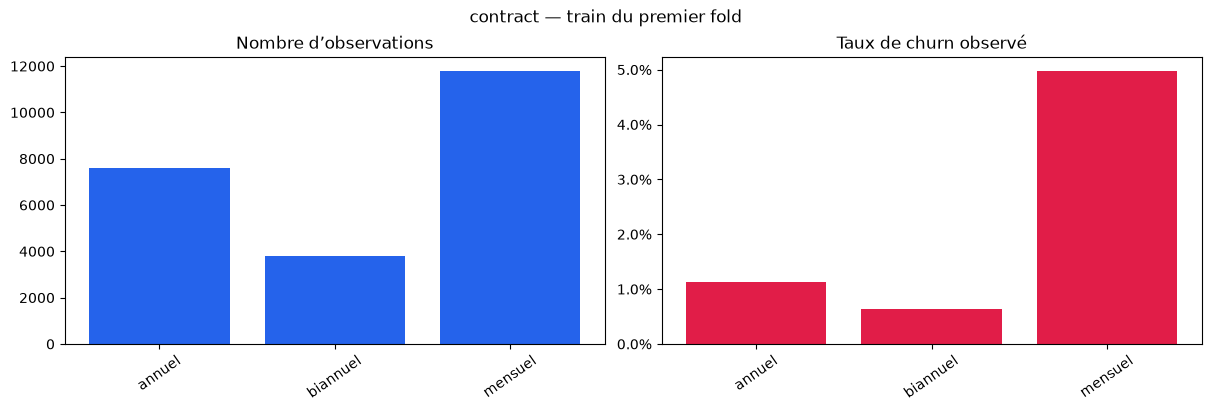

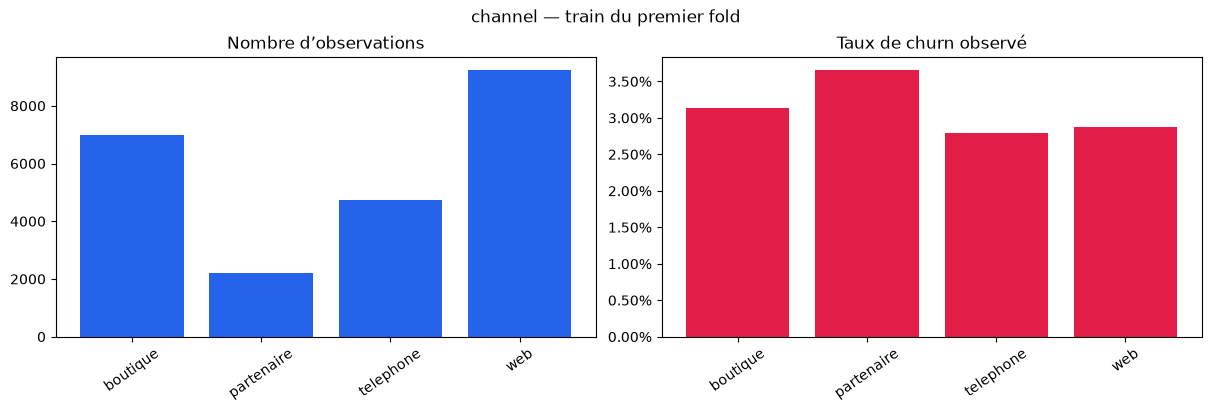

In [20]:
plot_group_analysis(analysis_data, CATEGORICAL_FEATURES)


**Numériques.** Lire les niveaux, les absences et le churn par tranche, puis repérer les redondances.
Les quantiles et la corrélation de Spearman ne constituent pas une règle de sélection automatique.


,count,mean,std,min,25%,50%,75%,max
monthly_fee,21962.0,60.68,18.28,10.34,48.42,60.56,72.72,130.39
data_gb,23174.0,73.82,801.52,0.00,1.90,3.70,6.80,32154.00
support_calls_3m,23174.0,1.14,1.16,0.00,0.00,1.00,2.00,10.00
late_payments,23174.0,0.40,0.64,0.00,0.00,0.00,1.00,4.00
nps,7421.0,6.78,1.98,-0.00,5.00,7.00,8.00,10.00
last_invoice_amount,23174.0,59.69,18.86,2.41,47.24,59.86,72.14,130.39


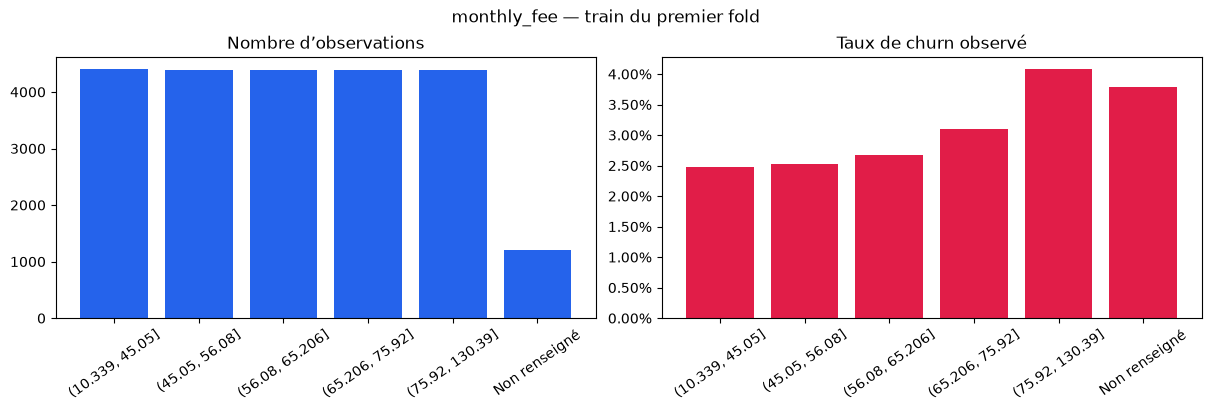

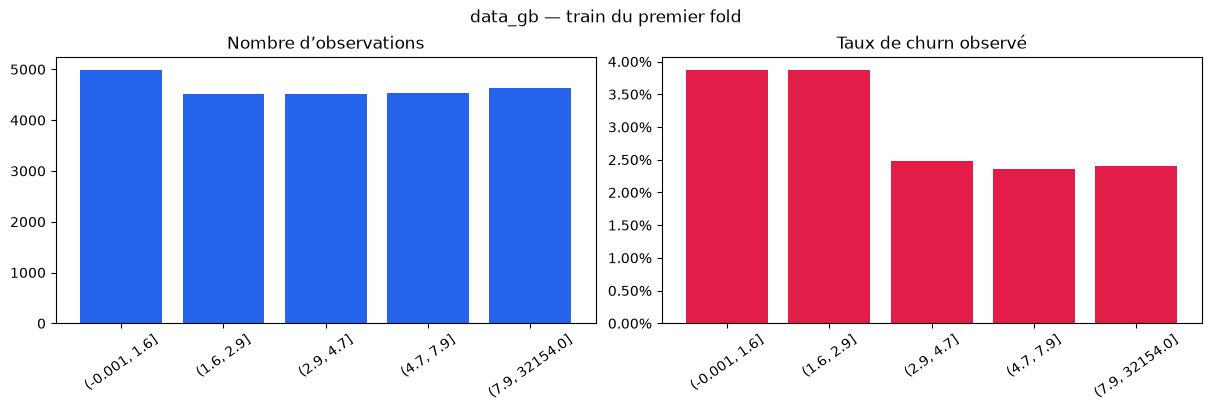

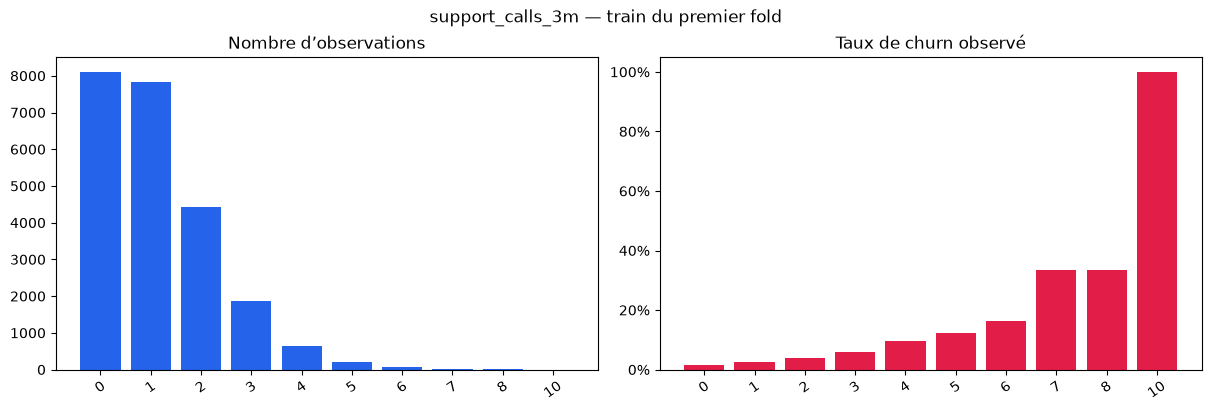

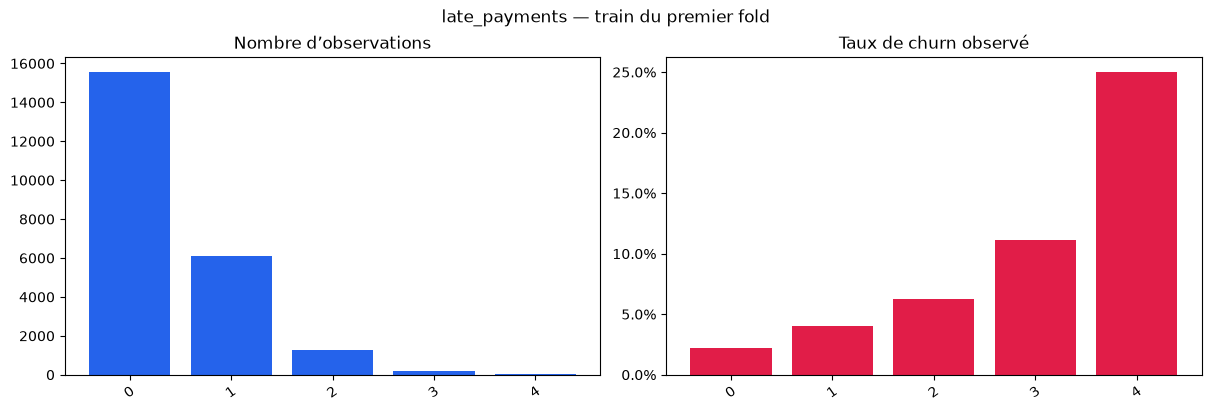

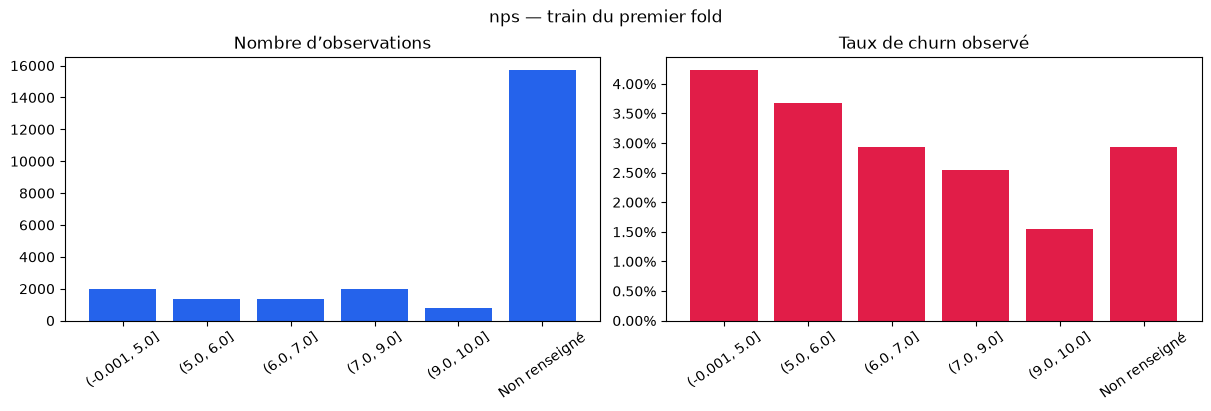

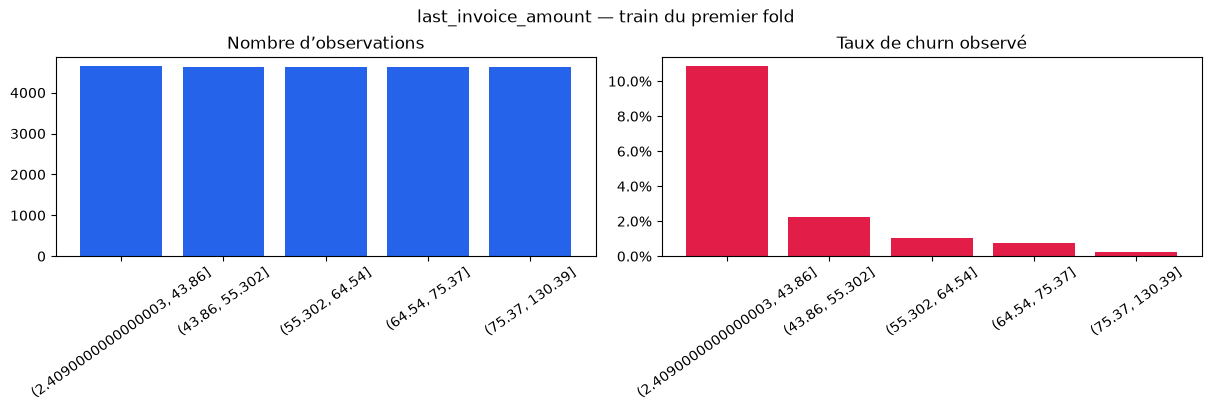

,monthly_fee,data_gb,support_calls_3m,late_payments,nps,last_invoice_amount,churn
monthly_fee,1.000,-0.010,-0.016,0.005,0.018,0.959,0.033
data_gb,-0.010,1.000,-0.002,-0.004,-0.007,-0.006,-0.038
support_calls_3m,-0.016,-0.002,1.000,0.057,-0.237,-0.040,0.102
late_payments,0.005,-0.004,0.057,1.000,-0.116,-0.014,0.073
nps,0.018,-0.007,-0.237,-0.116,1.000,0.028,-0.052
last_invoice_amount,0.959,-0.006,-0.040,-0.014,0.028,1.000,-0.209
churn,0.033,-0.038,0.102,0.073,-0.052,-0.209,1.000


In [21]:
display(analysis_data[NUMERIC_FEATURES].describe().T.round(2))
plot_group_analysis(analysis_data, NUMERIC_FEATURES)
display(analysis_data[NUMERIC_FEATURES + ["churn"]].corr(method="spearman").round(3))


### Choisir les variables à garder

Modifier uniquement `SELECTED_FEATURES` avec les noms exacts à conserver.
`None` lance la référence seule, sans inventer une sélection. Une liste lance aussi le second modèle.
Une colonne retirée ne sera pas réintroduite pendant l’entraînement.


In [22]:
SELECTED_FEATURES = None  # Exemple de syntaxe : ["contract", "monthly_fee", ...]

feature_sets = {"Référence": MODEL_FEATURES}
if SELECTED_FEATURES is not None:
    selection = select_features(SELECTED_FEATURES, MODEL_FEATURES, CATEGORICAL_FEATURES)
    feature_sets["Sélection manuelle"] = selection["features"]
    display(selection["decisions"])
else:
    print("Référence seule : renseigner SELECTED_FEATURES pour ajouter la comparaison.")

display(pd.DataFrame([
    {"Modèle": name, "Nombre": len(features), "Colonnes": ", ".join(features)}
    for name, features in feature_sets.items()
]).set_index("Modèle"))


Référence seule : renseigner SELECTED_FEATURES pour ajouter la comparaison.


,Nombre,Colonnes
Modèle,,
Référence,8,"contract, channel, monthly_fee, data_gb, suppo..."


### Comparer en validation croisée

Chaque client de développement est évalué une seule fois, hors de son train.
Le premier tableau donne les scores cumulés ; le second montre les différences entre folds.
Le MCC varie de −1 à 1 ; une valeur proche de 1 indique un meilleur accord entre prédictions et réalité.


In [23]:
experiments = []
for name, features in feature_sets.items():
    categories = [f for f in CATEGORICAL_FEATURES if f in features]
    experiments.append(run_grouped_cv(name, development, cv_splits, features, categories))

validation_scores = compare_experiments(experiments, "Validation")
display(validation_scores.round(4))
fold_scores = pd.concat([
    get_fold_metrics(experiment).assign(Modèle=experiment["name"])
    for experiment in experiments
]).set_index("Modèle", append=True)
display(fold_scores.round(4))


Référence — colonnes : ['contract', 'channel', 'monthly_fee', 'data_gb', 'support_calls_3m', 'late_payments', 'nps', 'last_invoice_amount']
Fold 1 : 8 variables, 500 itérations.
Fold 2 : 8 variables, 500 itérations.
Fold 3 : 8 variables, 500 itérations.
Fold 4 : 8 variables, 500 itérations.


,Variables,Average Precision,ROC-AUC,MCC,Logloss,F1,Precision,Recall
Modèle,,,,,,,,
Référence,8,0.9785,0.9955,0.9273,0.017,0.9292,0.9069,0.9527


,,Average Precision,ROC-AUC,MCC,Logloss,F1,Precision,Recall
Fold,Modèle,,,,,,,
Fold 1,Référence,0.9881,0.9972,0.9310,0.0150,0.9328,0.9098,0.9569
Fold 2,Référence,0.9744,0.9936,0.9163,0.0186,0.9186,0.8943,0.9442
Fold 3,Référence,0.9834,0.9981,0.9282,0.0174,0.9298,0.8964,0.9657
Fold 4,Référence,0.9689,0.9932,0.9339,0.0171,0.9359,0.9280,0.9440


### Évaluer sur les clients du test

Les choix sont fixés avant cette étape. Chaque modèle final est réentraîné sur tout le développement.
Ces résultats servent au bilan : ne pas ajuster la sélection en cherchant le meilleur score de test.


In [24]:
for experiment in experiments:
    run_final_test(experiment, splits["final_split"])
test_scores = compare_experiments(experiments, "Test")
display(test_scores.round(4))


Test final : 8 variables, 500 itérations.


,Variables,Average Precision,ROC-AUC,MCC,Logloss,F1,Precision,Recall
Modèle,,,,,,,,
Référence,8,0.9866,0.9992,0.939,0.0156,0.9407,0.925,0.9569


### Courbes, matrices et importance

La validation des matrices regroupe les prédictions hors train des quatre folds ; le test concerne d’autres clients.
Les courbes utilisent le premier fold. L’importance décrit l’utilisation des variables par le modèle final, sans prouver leur causalité.


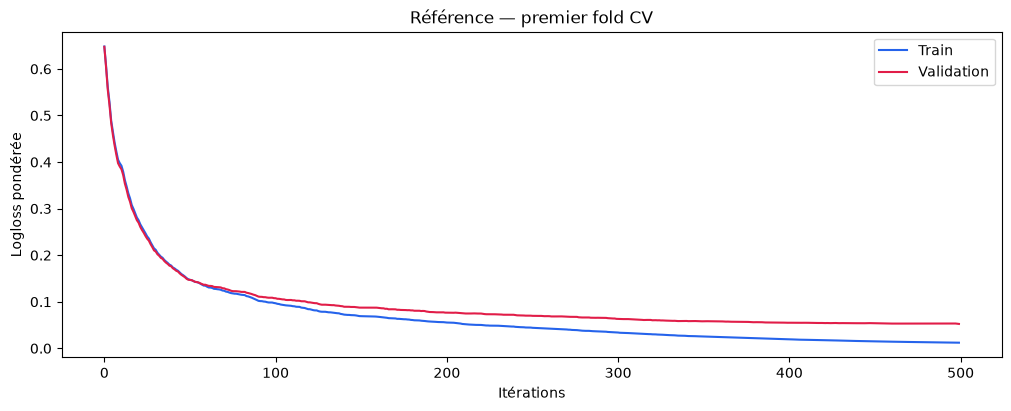

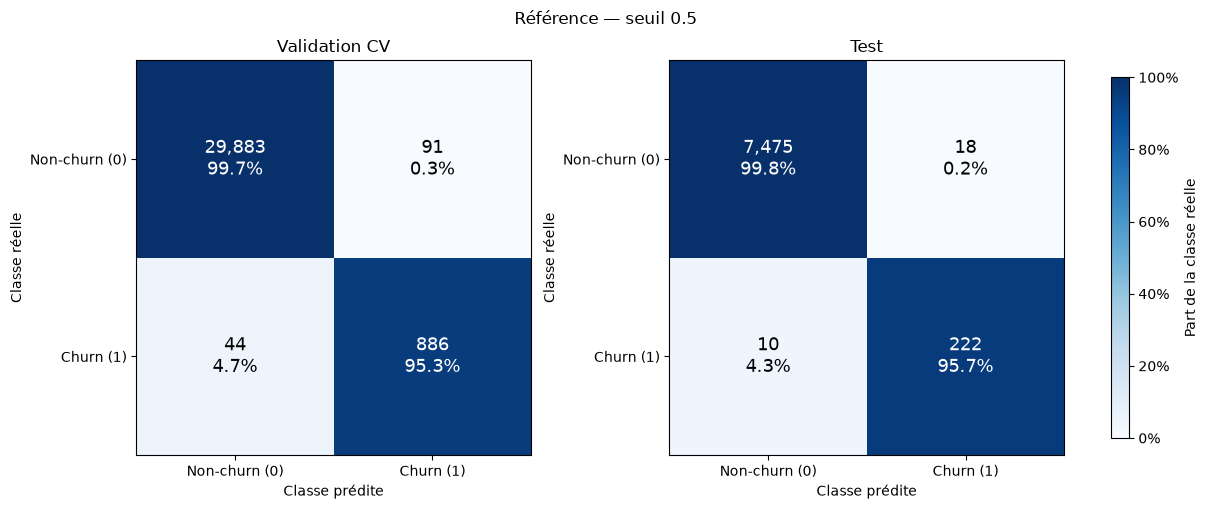

,importance
monthly_fee,47.116055
last_invoice_amount,33.451827
contract,5.131680
data_gb,4.987415
support_calls_3m,3.156148
late_payments,2.532199
nps,2.011373
channel,1.613303


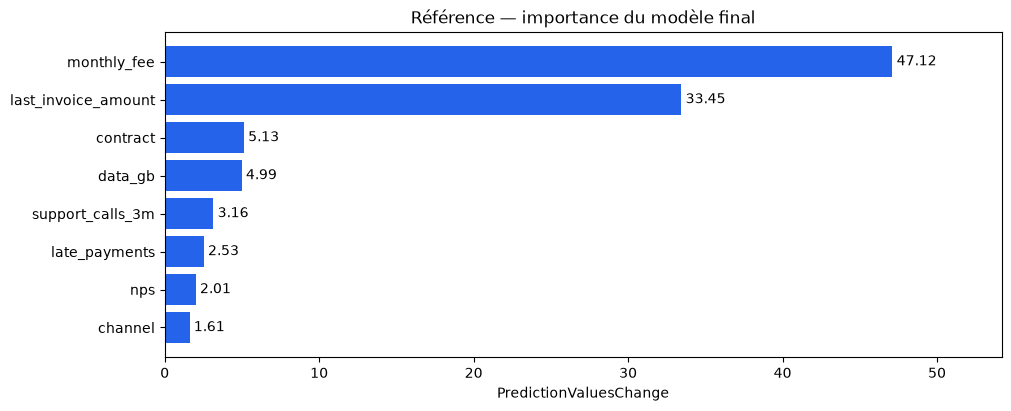

In [25]:
for experiment in experiments:
    plot_learning_curve(experiment)
    plot_confusion_matrices(experiment)
    plot_feature_importance(experiment)
